# EDA round 3: how should the data be transformed?

Rounds 1-2 asked *what is in the data* and *what makes the problem hard*. This round asks the
engineering question directly: **given tree models, which transformations actually create
signal?**

A framing constraint that prunes most of the search space: **trees are invariant to monotonic
transforms of a single column.** Rescaling, logging or min-max normalising one feature does
literally nothing to an XGBoost model. Only transforms that *combine* information can help, and
there are exactly four such families:

1. **Column combinations** - differences, ratios, spreads between two columns
2. **Time-window aggregates** - relative to a case, a day, a rolling window
3. **Graph/space aggregates** - across reservoirs, plants, the cascade
4. **Cross-sectional ranks** - position within a group

This notebook measures which of these actually pay.


In [1]:
import sys, re, warnings
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

INK, INK2, MUTED, GRID, BASE, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
CAT = ["#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4","#008300","#4a3aa7","#e34948"]
plt.rcParams.update({"figure.facecolor":SURF,"axes.facecolor":SURF,"axes.edgecolor":BASE,
    "axes.labelcolor":INK2,"axes.titlecolor":INK,"text.color":INK,"xtick.color":MUTED,
    "ytick.color":MUTED,"grid.color":GRID,"axes.grid":True,"grid.linewidth":0.8,
    "axes.spines.top":False,"axes.spines.right":False,"font.size":11,"figure.dpi":110})

train = pd.read_parquet("../../data/processed/train_hourly.parquet")
train["year"] = train["starttime"].dt.year
units = [c[3:] for c in train.columns if c.startswith("on_")]
y_pool = train[[f"on_{u}" for u in units]].mean(axis=1)
uc = pd.read_csv("../../data/kernel/Unit_commitment_decisions.csv").sort_values("Run No").reset_index(drop=True)
uc["starttime"] = pd.to_datetime(uc["starttime"])
san = lambda u: u.replace(" ","_")
M = {san(u): uc[[f"result_committed_{u}_t{t}" for t in range(168)]].to_numpy()
     for u in sorted({re.match(r"result_committed_(.+)_t\d+$",c).group(1)
                      for c in uc.columns if c.startswith("result_committed_")})}
with open("../../data/extended/Tokke_Vinje_topology.yaml") as f: topo = yaml.safe_load(f)
print(f"{len(train):,} rows, {len(units)} units")


490,896 rows, 14 units


## 1. Normalisation: which component actually creates the signal?

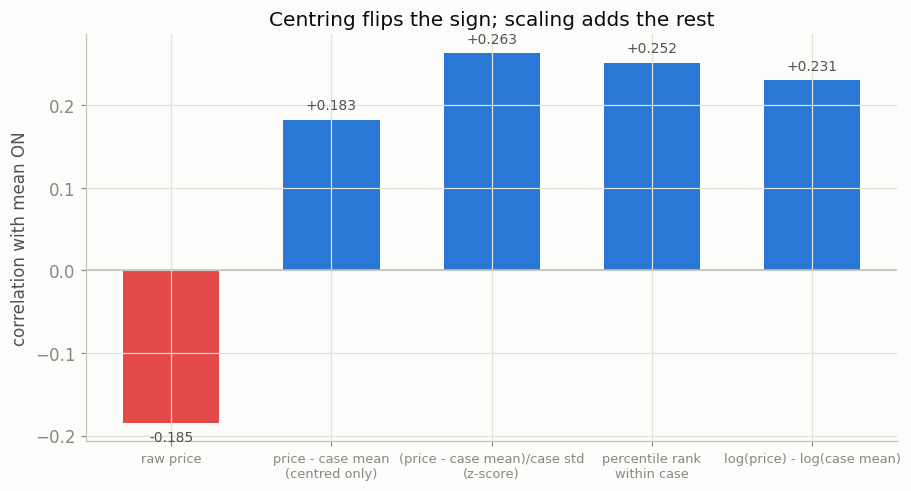

raw price                                 -0.1845
price - case mean\n(centred only)          0.1827
(price - case mean)/case std\n(z-score)    0.2633
percentile rank\nwithin case               0.2517
log(price) - log(case mean)                0.2309


In [2]:
g = train.groupby("run_no")["price_eur_mwh"]
case_mean, case_std, case_rank = g.transform("mean"), g.transform("std"), g.rank(pct=True)
p = train["price_eur_mwh"]
variants = {
    "raw price": p,
    "price - case mean\n(centred only)": p - case_mean,
    "(price - case mean)/case std\n(z-score)": (p - case_mean)/case_std,
    "percentile rank\nwithin case": case_rank,
    "log(price) - log(case mean)": np.log(p.clip(lower=0.1)) - np.log(case_mean.clip(lower=0.1)),
}
res = pd.Series({k: y_pool.corr(v) for k, v in variants.items()})

fig, ax = plt.subplots(figsize=(8.5,4.6))
cols = [CAT[7] if v < 0 else CAT[0] for v in res.values]
ax.bar(range(len(res)), res.values, color=cols, width=0.6)
ax.axhline(0, color=BASE, lw=1)
ax.set_xticks(range(len(res)), res.index, fontsize=8.5)
ax.set_ylabel("correlation with mean ON")
ax.set_title("Centring flips the sign; scaling adds the rest")
for i,v in enumerate(res.values):
    ax.text(i, v + (0.012 if v>0 else -0.022), f"{v:+.3f}", ha="center", fontsize=9, color=INK2)
plt.tight_layout(); plt.show()
print(res.round(4).to_string())


**Finding 1.** Raw price correlates **−0.18** with commitment; subtracting the case mean flips it
to **+0.18**; dividing by the case's own standard deviation takes it to **+0.26**. So the two
operations do different jobs: **centring removes the cross-period scarcity confound** (high-price
years are scarce-water years), and **scaling makes a ±5 EUR deviation in 2015 comparable to a
±100 EUR deviation in 2022**. Percentile rank within the case (+0.25) captures nearly all of it
with no distributional assumptions.

> **Feature rule.** Price features should be case-relative and scale-free (z-score or percentile),
> never raw levels.


## 2. ...but do NOT normalise the spread

In [3]:
wv = train["water_value_Vinjevatn"]
spread = p - wv
gs = spread.groupby(train["run_no"])
comp = pd.Series({
    "price - water value (raw spread)": train["on_Tokke_G1"].corr(spread),
    "spread, z-scored within case": train["on_Tokke_G1"].corr((spread-gs.transform("mean"))/gs.transform("std")),
    "spread, percentile within case": train["on_Tokke_G1"].corr(gs.rank(pct=True)),
})
print(comp.round(4).to_string())


price - water value (raw spread)    0.2408
spread, z-scored within case        0.1139
spread, percentile within case      0.1200


**Finding 2.** The opposite rule applies to the **price − water value spread**: raw **+0.241**,
z-scored within case **+0.114**. The spread is *already* a relative quantity — price measured
against its own opportunity cost — so normalising it a second time destroys the cross-case level
information that carries the signal. Normalise price; do **not** normalise the spread.


## 3. The optimizer is forward-looking: where does price signal live in time?

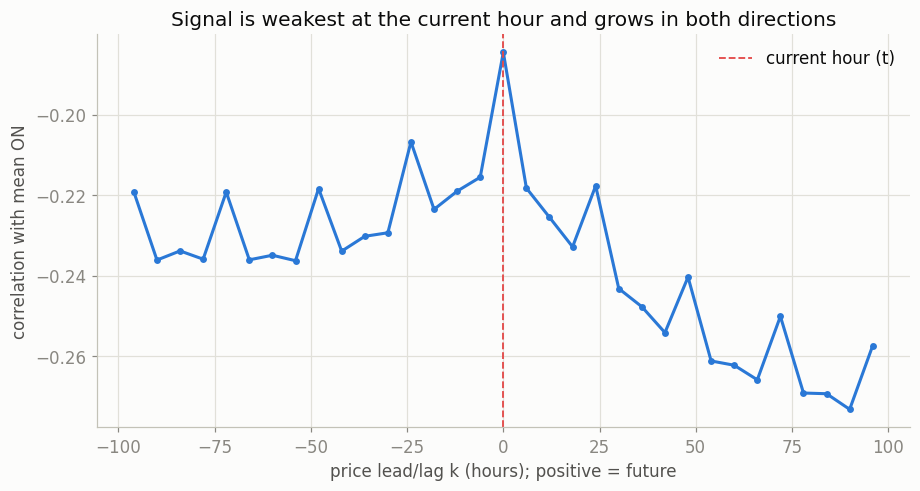

weakest |corr| at k=0h (-0.1845); strongest at k=90h (-0.2733)


In [4]:
price = pd.read_csv("../../data/kernel/Historical_day_ahead_price_2015_2025.csv")
price["date"] = pd.to_datetime(price["date"]).dt.tz_localize(None)
ps = price.set_index("date")["Day-ahead price (EUR/MWh)"].sort_index().loc["2014-12-01":"2023-02-01"]
idx = pd.date_range(ps.index.min(), ps.index.max(), freq="h")
arr = ps.reindex(idx).interpolate().to_numpy(); base = idx[0]
pos = ((train["timestamp"]-base)/pd.Timedelta(hours=1)).astype(int).to_numpy()

ks = np.arange(-96, 97, 6)
cc = [np.corrcoef(y_pool, arr[pos+k])[0,1] for k in ks]

fig, ax = plt.subplots(figsize=(8.5,4.6))
ax.plot(ks, cc, color=CAT[0], lw=2, marker="o", ms=3.5)
ax.axvline(0, color=CAT[7], lw=1.2, ls="--", label="current hour (t)")
ax.set_xlabel("price lead/lag k (hours); positive = future"); ax.set_ylabel("correlation with mean ON")
ax.set_title("Signal is weakest at the current hour and grows in both directions")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
print(f"weakest |corr| at k={ks[np.argmin(np.abs(cc))]}h ({min(cc, key=abs):+.4f}); "
      f"strongest at k={ks[int(np.argmax(np.abs(cc)))]}h ({cc[int(np.argmax(np.abs(cc)))]:+.4f})")


**Finding 3.** The price/commitment correlation is **weakest at the current hour** and strengthens
in *both* directions, reaching its maximum at roughly ±72–96h. Two things follow: the optimizer
genuinely uses the whole horizon (future price matters as much as present), and the *sustained
level* of price over multi-day windows matters more than the instantaneous value — consistent
with the scarcity story. Forward-looking window features are legitimate here because the whole
168h price path is known at solve time.


## 4. The 17 water-value columns are essentially one signal

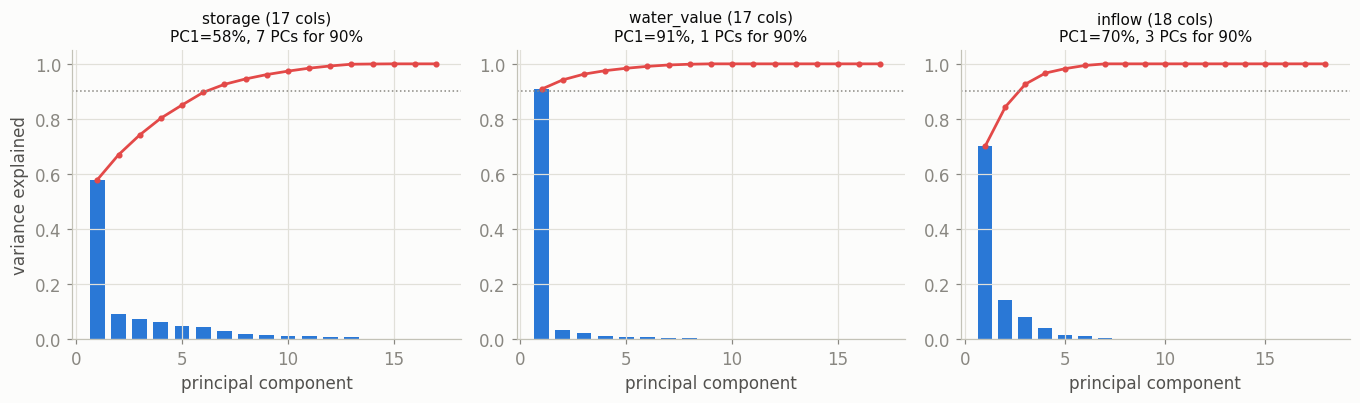

storage_      : 17 columns -> PC1 57.9%, 7 PCs reach 90%
water_value_  : 17 columns -> PC1 90.8%, 1 PCs reach 90%
inflow_       : 18 columns -> PC1 70.3%, 3 PCs reach 90%


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))
info = {}
for ax, grp in zip(axes, ["storage_", "water_value_", "inflow_"]):
    cols = [c for c in train.columns if c.startswith(grp)]
    X = train[cols].to_numpy(); X = X[:, X.std(0) > 0]
    Xs = (X - X.mean(0))/X.std(0)
    ev = np.linalg.svd(np.cov(Xs.T), compute_uv=False); ev = ev/ev.sum()
    cum = np.cumsum(ev)
    k90 = int(np.searchsorted(cum, 0.90)) + 1
    info[grp] = (len(cols), ev[0], k90)
    ax.bar(range(1, len(ev)+1), ev, color=CAT[0], width=0.7)
    ax.plot(range(1, len(ev)+1), cum, color=CAT[7], lw=1.8, marker="o", ms=3)
    ax.axhline(0.9, color=MUTED, lw=1, ls=":")
    ax.set_title(f"{grp.rstrip('_')} ({len(cols)} cols)\nPC1={ev[0]:.0%}, {k90} PCs for 90%", fontsize=10)
    ax.set_xlabel("principal component")
axes[0].set_ylabel("variance explained")
plt.tight_layout(); plt.show()
for g_, (n, pc1, k) in info.items():
    print(f"{g_:14s}: {n:>2} columns -> PC1 {pc1:.1%}, {k} PCs reach 90%")


**Finding 4.** The 17 **water-value** columns have **PC1 = 91%** — they are effectively *one*
system-wide scarcity factor. Inflow needs 3 components for 90%, storage 7. So adding more
per-reservoir water-value features is near-useless; the informative decomposition is
**(system common factor) + (reservoir-specific deviation)**.


## 5. Graph aggregation: own reservoir vs. system vs. the difference

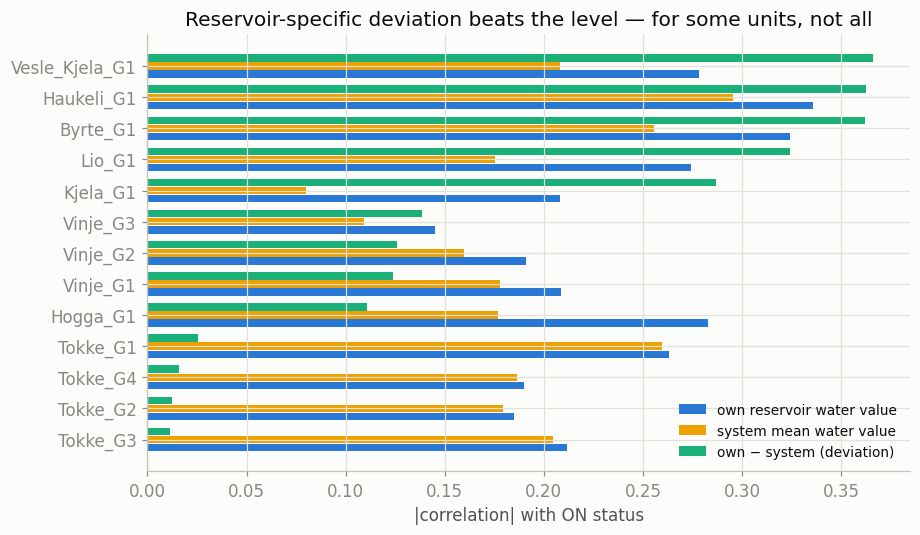

                own reservoir  system mean  own - system
unit                                                    
Tokke_G3                0.212        0.204         0.011
Tokke_G2                0.185        0.180         0.012
Tokke_G4                0.190        0.186         0.016
Tokke_G1                0.263        0.259         0.025
Hogga_G1                0.283        0.177         0.111
Vinje_G1                0.209        0.178         0.124
Vinje_G2                0.191        0.160         0.126
Vinje_G3                0.145        0.109         0.139
Kjela_G1                0.208        0.080         0.287
Lio_G1                  0.274        0.175         0.324
Byrte_G1                0.324        0.256         0.362
Haukeli_G1              0.336        0.296         0.363
Vesle_Kjela_G1          0.278        0.208         0.366


In [6]:
plant_res = {c["to"]: c["from"] for c in topo["connections"]
             if c["to_type"]=="plant" and c["from_type"]=="reservoir"}
allres = [c[len("water_value_"):] for c in train.columns if c.startswith("water_value_")]
sys_wv = train[[f"water_value_{r}" for r in allres]].mean(axis=1)
rows=[]
for u in units:
    pl = u.rsplit("_G",1)[0]
    r = plant_res.get(pl) or plant_res.get(pl.replace("_"," "))
    if r is None: continue
    y = train[f"on_{u}"]
    rows.append({"unit":u, "own reservoir":abs(y.corr(train[f"water_value_{r}"])),
                 "system mean":abs(y.corr(sys_wv)),
                 "own - system":abs(y.corr(train[f"water_value_{r}"]-sys_wv))})
gdf = pd.DataFrame(rows).set_index("unit").sort_values("own - system")

fig, ax = plt.subplots(figsize=(8.5,5))
yy = np.arange(len(gdf))
ax.barh(yy-0.26, gdf["own reservoir"], height=0.24, color=CAT[0], label="own reservoir water value")
ax.barh(yy,      gdf["system mean"],   height=0.24, color=CAT[3], label="system mean water value")
ax.barh(yy+0.26, gdf["own - system"],  height=0.24, color=CAT[2], label="own − system (deviation)")
ax.set_yticks(yy, gdf.index); ax.set_xlabel("|correlation| with ON status")
ax.set_title("Reservoir-specific deviation beats the level — for some units, not all")
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()
print(gdf.round(3).to_string())


**Finding 5.** The **own − system** water-value deviation is the strongest of the three for
Vesle_Kjela_G1 (0.366 vs 0.278), Byrte_G1 (0.362 vs 0.324), Haukeli_G1, Kjela_G1 and Lio_G1 —
units on reservoirs that diverge from the system factor. For the **Tokke** units it is ~0.01,
because Vinjevatn tracks the system almost perfectly. So graph/neighbourhood features help
*selectively*, and per-unit, which is exactly what a plain global feature set cannot express.


## 6. The unused boundary condition: terminal water value

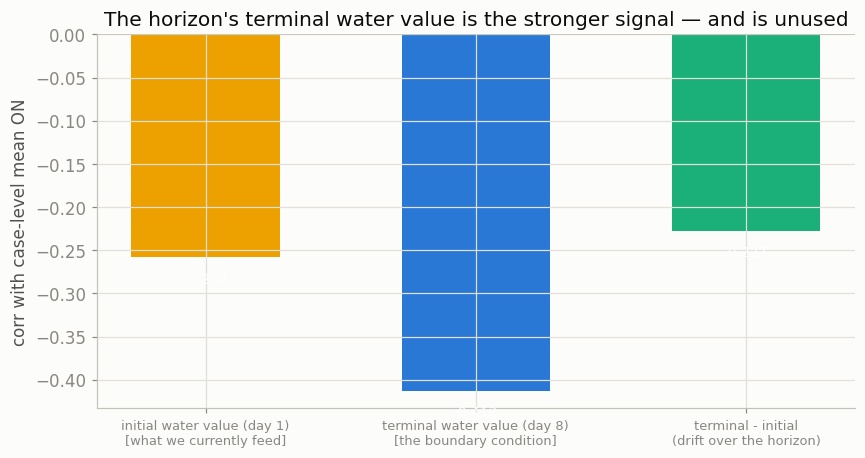

fraction of (case, reservoir) pairs where terminal != initial: 93.4%


In [7]:
wvf = pd.read_csv("../../data/kernel/Synthetic_water_value_2015_2024.csv")
wvf["date"] = pd.to_datetime(wvf["date"]).dt.tz_localize(None); wvf = wvf.set_index("date")
start_wv = wvf.reindex(uc["starttime"]).to_numpy()
end_wv   = wvf.reindex(uc["starttime"] + pd.Timedelta(days=8)).to_numpy()
case_on  = np.mean([M[u].mean(axis=1) for u in units], axis=0)
i = list(wvf.columns).index("Vinjevatn"); ok = ~np.isnan(end_wv[:, i])
comp = pd.Series({
    "initial water value (day 1)\n[what we currently feed]": np.corrcoef(case_on[ok], start_wv[ok,i])[0,1],
    "terminal water value (day 8)\n[the boundary condition]": np.corrcoef(case_on[ok], end_wv[ok,i])[0,1],
    "terminal - initial\n(drift over the horizon)": np.corrcoef(case_on[ok], (end_wv-start_wv)[ok,i])[0,1],
})
fig, ax = plt.subplots(figsize=(8,4.3))
ax.bar(range(3), comp.values, color=[CAT[3], CAT[0], CAT[2]], width=0.55)
ax.axhline(0, color=BASE, lw=1); ax.set_xticks(range(3), comp.index, fontsize=8.5)
ax.set_ylabel("corr with case-level mean ON")
ax.set_title("The horizon's terminal water value is the stronger signal — and is unused")
for j,v in enumerate(comp.values): ax.text(j, v-0.03, f"{v:+.3f}", ha="center", fontsize=9, color="white")
plt.tight_layout(); plt.show()
print(f"fraction of (case, reservoir) pairs where terminal != initial: "
      f"{np.nanmean(np.abs(end_wv-start_wv)>0.01):.1%}")


**Finding 6.** The dataset documentation states that a case's *final* water value is the value at
start + 8 days. We feed the model the **initial** value and never the terminal one. The terminal
value correlates **−0.41** with the case's overall commitment level versus **−0.26** for the
initial value, and the two differ in **93%** of case/reservoir pairs. This is a genuine
per-case boundary condition sitting unused in the data — a strong candidate for part of the gap
between our score and what is achievable.


## 7. Two hypotheses tested and refuted

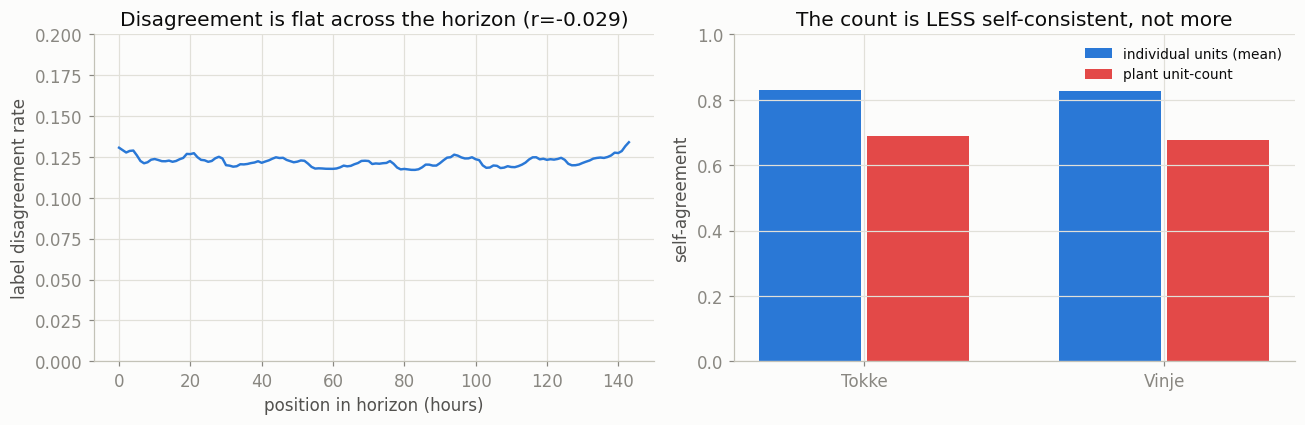

In [8]:
dis = np.zeros(144)
for u in units:
    dis += (M[u][:-1,24:168] != M[u][1:,0:144]).mean(axis=0)
dis /= len(units)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(144), dis, color=CAT[0], lw=1.6)
axes[0].set_ylim(0, 0.2); axes[0].set_xlabel("position in horizon (hours)")
axes[0].set_ylabel("label disagreement rate")
axes[0].set_title(f"Disagreement is flat across the horizon (r={np.corrcoef(np.arange(144),dis)[0,1]:+.3f})")

names, unit_a, cnt_a = [], [], []
for plant, gu in [("Tokke",["Tokke_G1","Tokke_G2","Tokke_G3","Tokke_G4"]),
                   ("Vinje",["Vinje_G1","Vinje_G2","Vinje_G3"])]:
    cnt = sum(M[g] for g in gu)
    names.append(plant)
    unit_a.append(np.mean([(M[g][:-1,24:168]==M[g][1:,0:144]).mean() for g in gu]))
    cnt_a.append((cnt[:-1,24:168]==cnt[1:,0:144]).mean())
x = np.arange(len(names))
axes[1].bar(x-0.18, unit_a, width=0.34, color=CAT[0], label="individual units (mean)")
axes[1].bar(x+0.18, cnt_a, width=0.34, color=CAT[7], label="plant unit-count")
axes[1].set_xticks(x, names); axes[1].set_ylim(0,1); axes[1].set_ylabel("self-agreement")
axes[1].set_title("The count is LESS self-consistent, not more")
axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()


**Finding 7 (refuted).** I expected label disagreement to concentrate near the end of the horizon,
since that is where the boundary condition bites. It does not — disagreement is **flat**
(r = −0.03). The terminal water value shapes the *whole* week's schedule rather than just its
tail, which is consistent with Finding 6 but not with a tail-concentrated effect. No
horizon-position sample weighting is justified.

**Finding 8 (refuted).** I predicted per-plant *counts* would be less noisy than individual units.
They are **more** noisy (Tokke 0.688 vs 0.829) — obvious in hindsight, since a sum disagrees
whenever any term does. This does **not** invalidate the count-based architecture from round 2
(count → exact pattern is still 97.8%/99.9% accurate), but the justification for it is the
merit-order determinism, *not* a noise reduction. Claim corrected.


## Summary: the transformation rules this round establishes

| Rule | Evidence |
|---|---|
| Price features must be **case-relative and scale-free** (z-score / percentile) | raw −0.18 → centred +0.18 → z-scored +0.26 |
| **Do not** normalise the price−water-value spread | raw +0.241 vs z-scored +0.114 |
| Use **multi-day forward and backward** price windows, not the current hour | |corr| minimised at k=0, maximised at ±72–96h |
| Water value is **one factor + deviations**; don't add 17 correlated columns | PC1 = 91% of variance |
| **own − system** deviations help *selectively*, per unit | best for Vesle_Kjela/Byrte/Kjela; ~0 for Tokke |
| Feed the **terminal (day-8) water value**, not just the initial | −0.41 vs −0.26; differs in 93% of cases |
| No horizon-position weighting; counts are not a noise reduction | both hypotheses refuted above |
